# Predicting Stock Market Prices	
Execute rigorous outlier detection and treatment strategies on the Volume column using the Interquartile Range (IQR) method, ensuring the removal of anomalies that may distort trend analysis.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [8]:
from pathlib import Path
import pandas as pd

# Show the current notebook folder
print("Current folder:", Path.cwd())

# Find all CSV files in the current folder and its subfolders
csv_files = list(Path.cwd().rglob("*.csv"))


# Select the correct dataset
matches = [
    file for file in csv_files
    if file.name.lower() in ["tsla_cleaned_data.csv", "tsla_cleaned_data.csv.csv"]
]

if not matches:
    raise FileNotFoundError(
        "TSLA cleaned dataset not found. Check the CSV filenames printed above."
    )

FILE_PATH = matches[0]

df = pd.read_csv(FILE_PATH)

print("\nDataset loaded successfully!")
print("File:", FILE_PATH)
print("Shape:", df.shape)

display(df.head())

Current folder: d:\brainybeam\new\Heart Disease Prediction

Dataset loaded successfully!
File: d:\brainybeam\new\Heart Disease Prediction\TSLA_cleaned_data.csv
Shape: (100, 6)


,Date,Open,High,Low,Close,Volume
0,2025-04-29,402.54,404.82,400.82,402.89,96503640
1,2025-03-18,414.37,417.58,406.36,411.17,129923902
2,2025-04-10,406.52,410.38,403.81,409.23,113709729
3,2025-03-06,405.40,405.98,399.78,404.15,119732002
4,2025-03-05,411.49,415.52,399.13,402.75,48754535


In [9]:
if "Volume" not in df.columns:
    raise KeyError("The dataset does not contain a 'Volume' column.")

df["Volume"] = pd.to_numeric(df["Volume"], errors="coerce")
print("Volume data type:", df["Volume"].dtype)
print("Missing Volume values:", df["Volume"].isna().sum())
print("Negative Volume values:", (df["Volume"] < 0).sum())
display(df["Volume"].describe())

Volume data type: int64
Missing Volume values: 0
Negative Volume values: 0


count    1.000000e+02
mean     8.590925e+07
std      2.814561e+07
min      4.541570e+07
25%      5.631168e+07
50%      8.569552e+07
75%      1.130929e+08
max      1.299239e+08
Name: Volume, dtype: float64

In [10]:
volume = df["Volume"].dropna()
Q1 = volume.quantile(0.25)
Q3 = volume.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1: {Q1:,.2f}")
print(f"Q3: {Q3:,.2f}")
print(f"IQR: {IQR:,.2f}")
print(f"Lower bound: {lower_bound:,.2f}")
print(f"Upper bound: {upper_bound:,.2f}")

Q1: 56,311,675.50
Q3: 113,092,933.50
IQR: 56,781,258.00
Lower bound: -28,860,211.50
Upper bound: 198,264,820.50


In [11]:
outlier_mask = df["Volume"].notna() & ((df["Volume"] < lower_bound) | (df["Volume"] > upper_bound))
outliers = df.loc[outlier_mask].copy()

print("Potential Volume outliers:", len(outliers))
print("Percentage flagged:", round(len(outliers) / df["Volume"].notna().sum() * 100, 2), "%")
display(outliers.sort_values("Volume", ascending=False))

Potential Volume outliers: 0
Percentage flagged: 0.0 %


,Date,Open,High,Low,Close,Volume


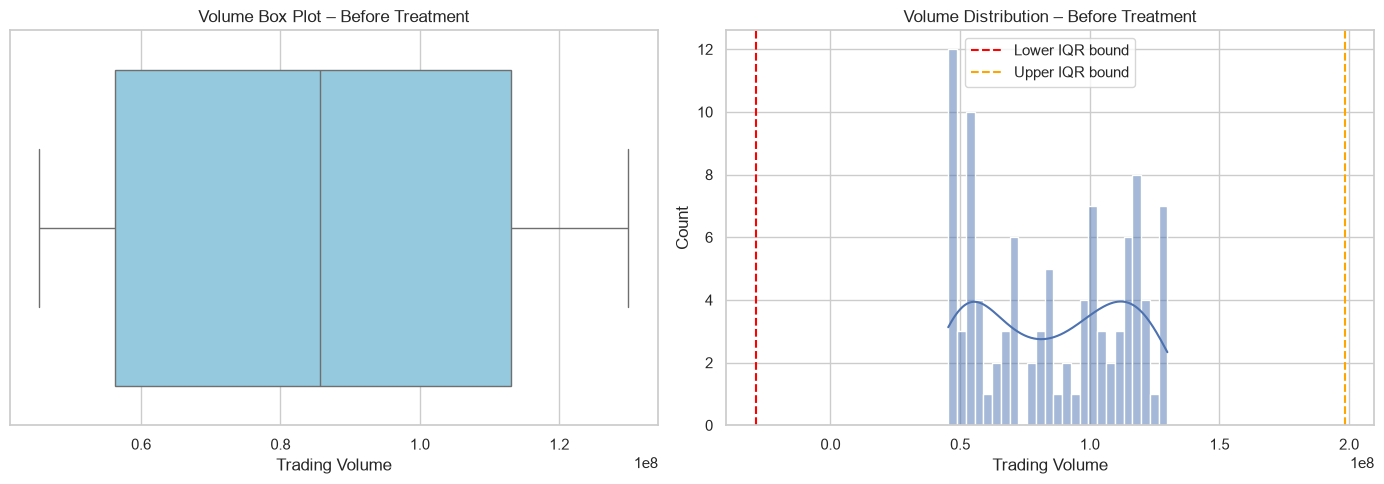

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x=df["Volume"], ax=axes[0], color="skyblue")
axes[0].set_title("Volume Box Plot – Before Treatment")
axes[0].set_xlabel("Trading Volume")
sns.histplot(df["Volume"].dropna(), bins=25, kde=True, ax=axes[1])
axes[1].axvline(lower_bound, color="red", linestyle="--", label="Lower IQR bound")
axes[1].axvline(upper_bound, color="orange", linestyle="--", label="Upper IQR bound")
axes[1].set_title("Volume Distribution – Before Treatment")
axes[1].set_xlabel("Trading Volume")
axes[1].legend()
plt.tight_layout()
plt.show()

In [13]:
df_clean = df.loc[~outlier_mask].copy()
print("Original row count:", len(df))
print("Removed outlier rows:", len(outliers))
print("Cleaned row count:", len(df_clean))
print("Outliers remaining:", ((df_clean["Volume"] < lower_bound) | (df_clean["Volume"] > upper_bound)).sum())
display(df_clean.head())

Original row count: 100
Removed outlier rows: 0
Cleaned row count: 100
Outliers remaining: 0


,Date,Open,High,Low,Close,Volume
0,2025-04-29,402.54,404.82,400.82,402.89,96503640
1,2025-03-18,414.37,417.58,406.36,411.17,129923902
2,2025-04-10,406.52,410.38,403.81,409.23,113709729
3,2025-03-06,405.40,405.98,399.78,404.15,119732002
4,2025-03-05,411.49,415.52,399.13,402.75,48754535


,Before treatment,After IQR removal
count,1.000000e+02,1.000000e+02
mean,8.590925e+07,8.590925e+07
std,2.814561e+07,2.814561e+07
min,4.541570e+07,4.541570e+07
25%,5.631168e+07,5.631168e+07
50%,8.569552e+07,8.569552e+07
75%,1.130929e+08,1.130929e+08
max,1.299239e+08,1.299239e+08


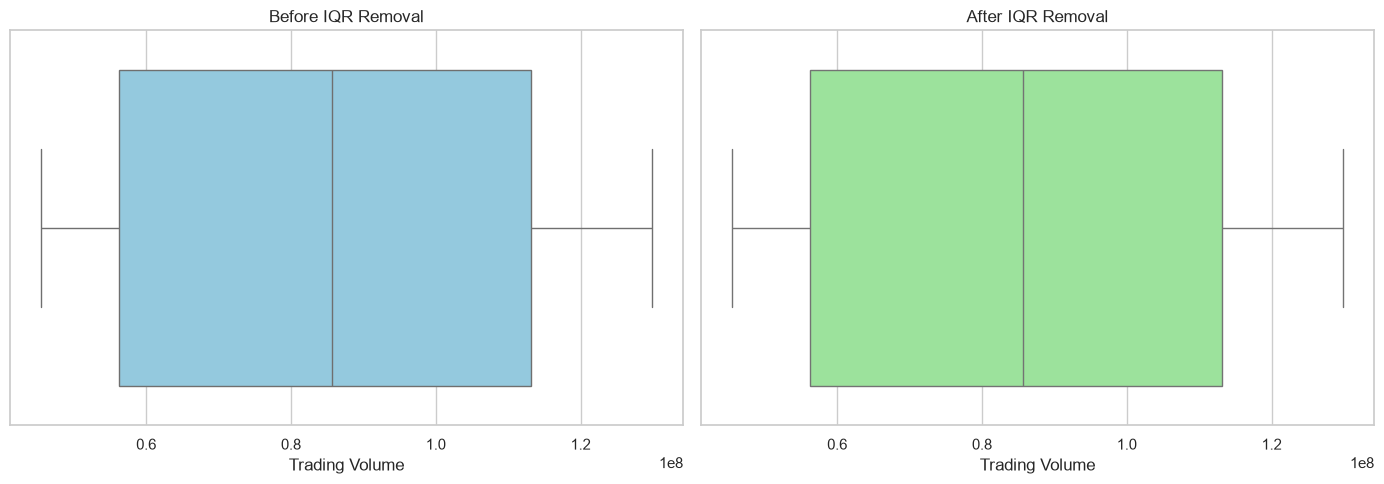

In [14]:
comparison = pd.DataFrame({"Before treatment": df["Volume"].describe(), "After IQR removal": df_clean["Volume"].describe()})
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x=df["Volume"], ax=axes[0], color="skyblue")
axes[0].set_title("Before IQR Removal")
axes[0].set_xlabel("Trading Volume")
sns.boxplot(x=df_clean["Volume"], ax=axes[1], color="lightgreen")
axes[1].set_title("After IQR Removal")
axes[1].set_xlabel("Trading Volume")
plt.tight_layout()
plt.show()